# Cambio tecnológico: horizonte de remediación CISA KEV

## Resumen

**Decisión:** explorar el plazo indicado en un catálogo de vulnerabilidades explotadas para diseñar un proceso interno de priorización. El análisis cuenta CVE en el catálogo, no activos afectados ni vulnerabilidades pendientes de una organización.

**Resultado del corte:** El snapshot contiene 1.779 CVE; no hay plazos negativos ni fechas faltantes.

## Contexto y método

Comparación descriptiva para apoyar preguntas de gestión. No se identifica causalidad ni se valida un modelo productivo.

In [1]:
from pathlib import Path
import hashlib
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
repo = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / '03-financial-risk').is_dir())
plt.rcParams.update({'figure.figsize': (9, 4.5), 'axes.grid': True, 'grid.alpha': .2, 'font.size': 10})

## Datos y procedencia

Fuente primaria: [CISA Known Exploited Vulnerabilities](https://www.cisa.gov/known-exploited-vulnerabilities-catalog), [CSV oficial](https://www.cisa.gov/sites/default/files/csv/known_exploited_vulnerabilities.csv). Snapshot local descargado el 12-11-2026; SHA-256 `85f484aba48c592c113722cb3e17e768fb5bd2f8f8ee7c548a2ed471e44efb85`. Los plazos son fechas CISA para agencias federales, no tiempo de remediación observado; catálogo selectivo de vulnerabilidades explotadas.

In [2]:
path = repo / '03-financial-risk/05-enterprise-risk-advisory/04-cyber-ai/technology-change/data/cisa_kev_2026-11-12.csv'
df=pd.read_csv(path,parse_dates=['dateAdded','dueDate'])
assert df.cveID.is_unique
assert hashlib.sha256(path.read_bytes()).hexdigest() == '85f484aba48c592c113722cb3e17e768fb5bd2f8f8ee7c548a2ed471e44efb85'
df['plazo_dias']=(df.dueDate-df.dateAdded).dt.days
print('CVE:',len(df),'| plazos negativos:',int((df.plazo_dias<0).sum()),'| fechas faltantes:',int(df.plazo_dias.isna().sum()))
display(df.plazo_dias.describe(percentiles=[.25,.5,.75,.9]).to_frame('días de plazo'))

CVE: 1779 | plazos negativos: 0 | fechas faltantes: 0


,días de plazo
count,1779.000000
mean,41.065205
std,57.853693
min,1.000000
25%,14.000000
50%,21.000000
75%,21.000000
90%,181.000000
max,184.000000


## Resultados

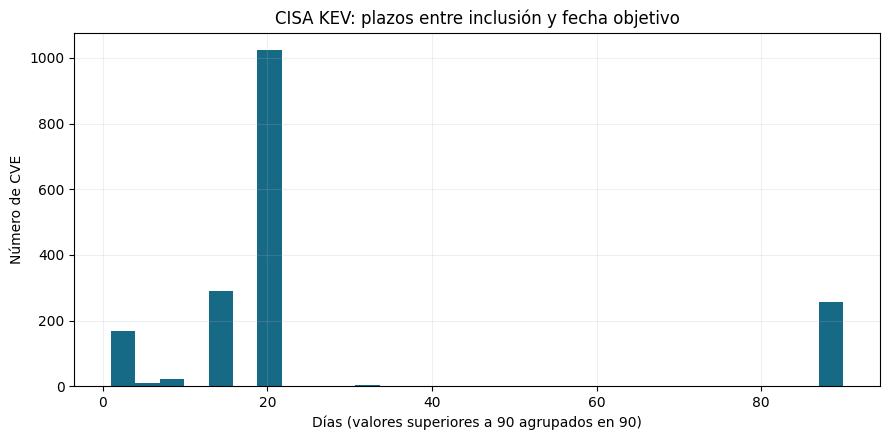

In [3]:
series=df.plazo_dias.dropna(); ax=series.clip(upper=90).plot.hist(bins=30,color='#176a86'); ax.set(title='CISA KEV: plazos entre inclusión y fecha objetivo',xlabel='Días (valores superiores a 90 agrupados en 90)',ylabel='Número de CVE'); plt.tight_layout(); plt.show()

### Calidad temporal y distribución sin truncar

El plazo es el intervalo entre la inclusión por CISA y la fecha objetivo publicada; no representa el tiempo que tardó una organización en remediar.

Fechas faltantes: 0 | plazos superiores a 90 días: 257
Mediana: 21 días | percentil 90: 181 días


,cve,mediana_dias,fechas_validas
ano,,,
2021,311,181.0,311
2022,555,21.0,555
2023,187,21.0,187
2024,186,21.0,186
2025,245,21.0,245
2026,295,3.0,295


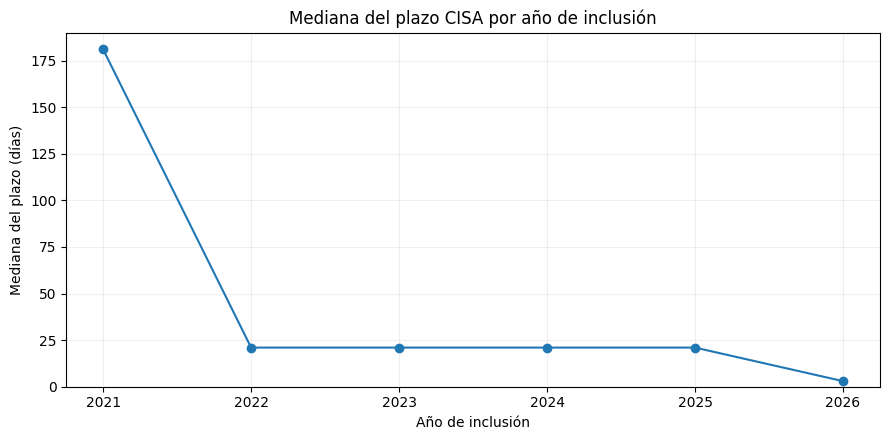

In [4]:
assert df.cveID.notna().all() and df.cveID.is_unique
valid=df.plazo_dias.dropna()
assert len(valid)>0 and (valid >= 0).all()
print('Fechas faltantes:',int(df.plazo_dias.isna().sum()),'| plazos superiores a 90 días:',int((valid>90).sum()))
print('Mediana:',f'{valid.median():.0f} días','| percentil 90:',f'{valid.quantile(.9):.0f} días')
by_year=df.assign(ano=df.dateAdded.dt.year).groupby('ano').agg(cve=('cveID','size'),mediana_dias=('plazo_dias','median'),fechas_validas=('plazo_dias','count'))
display(by_year.tail(8))
ax=by_year.mediana_dias.plot(marker='o',title='Mediana del plazo CISA por año de inclusión');ax.set(xlabel='Año de inclusión',ylabel='Mediana del plazo (días)',ylim=(0,None));plt.tight_layout();plt.show()

Las cohortes y políticas de CISA pueden variar entre años; una diferencia en la mediana no demuestra una mejora o deterioro en remediación efectiva.

## Variantes de umbral: proporciones del catálogo

Calculamos la fracción de entradas KEV con plazo publicado de hasta 7, 14 o 30 días. Son probabilidades empíricas de seleccionar una **entrada de este snapshot** que cumpla el umbral, condicionales a tener ambas fechas; no probabilidades de explotación, incumplimiento ni tiempo de parcheo. [CISA](https://www.cisa.gov/sites/default/files/publications/Reducing_the_Significant_Risk_of_Known_Exploited_Vulnerabilities_20211103.pdf) describe el catálogo y la directiva para agencias civiles federales estadounidenses: sus plazos no se interpretan como obligación automática para organizaciones colombianas. No hay fechas de remediación organizacional en esta fuente.

,umbral_dias,cve_con_fecha,cve_dentro_umbral,proporcion_catalogo
0,7,1779,196,0.1102
1,14,1779,490,0.2754
2,30,1779,1517,0.8527


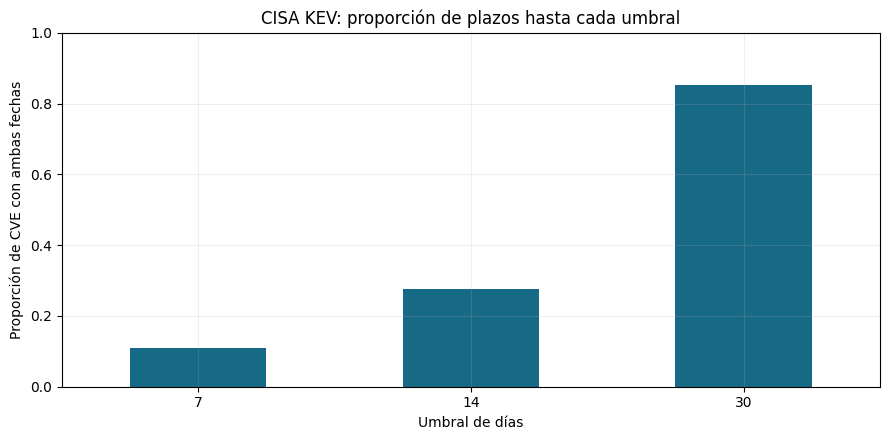

In [5]:
thresholds = [7, 14, 30]
assert len(valid)>0
metrics=pd.DataFrame([{'umbral_dias':t,'cve_con_fecha':len(valid),'cve_dentro_umbral':int((valid<=t).sum()),'proporcion_catalogo':(valid<=t).mean()} for t in thresholds])
assert metrics.proporcion_catalogo.between(0,1).all() and metrics.proporcion_catalogo.is_monotonic_increasing
display(metrics.round(4))
ax=metrics.plot.bar(x='umbral_dias',y='proporcion_catalogo',legend=False,color='#176a86');ax.set(title='CISA KEV: proporción de plazos hasta cada umbral',xlabel='Umbral de días',ylabel='Proporción de CVE con ambas fechas',ylim=(0,1));plt.xticks(rotation=0);plt.tight_layout();plt.show()

## Interpretación y límites

Una fecha objetivo pública no demuestra que una organización tenga el producto, ni que cumpla o incumpla el plazo. Para medir riesgo tecnológico son necesarios inventario de versiones, exposición, excepciones y fecha real de cierre; no extrapolar el catálogo a todos los CVE.

**Reproducción:** desde este repositorio ejecutar `python -m jupyter nbconvert --execute --to notebook --inplace 01_cisa_kev_priorizacion.ipynb` en la carpeta del proyecto; requiere Python, pandas, matplotlib, nbformat, nbclient e ipykernel.